# 09 — Entraîner, évaluer, générer

**Chapitre 2** · durée conseillée : 35 min · CPU : ≈ 2 à 4 min d'entraînement (lancez la cellule au début de l'explication)

![Parcours](figures/00_parcours.svg)

**À la fin de ce notebook, vous saurez :**
1. écrire et expliquer la boucle d'entraînement complète, avec évaluation régulière ;
2. lire une courbe train / validation et repérer le **surapprentissage** ;
3. évaluer un modèle de langage autrement qu'« à l'œil » : loss, perplexité, loss **par position**, comparaison au bigramme ;
4. regarder **ce qu'ont appris** les têtes d'attention ;
5. générer du texte et régler la **température**.

In [1]:
# Préparation : imports et module partagé du chapitre
import math
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import minigpt  # fichier minigpt.py, à côté de ce notebook
torch.manual_seed(1337)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| périphérique :", device)
import time

CORPUS = "shakespeare"        # essayez ensuite "kaamelott" ou "platon"
texte, tok, train_data, val_data = minigpt.preparer_donnees(CORPUS)
V = tok.vocab_size
print(f"{CORPUS} : V = {V}, train = {len(train_data):,}, val = {len(val_data):,}")

PyTorch 2.14.1+cu130 | périphérique : cpu
shakespeare : V = 65, train = 1,003,854, val = 111,540


## 1. Les hyperparamètres

| Nom | Valeur | Rôle |
|---|---|---|
| `batch_size` (B) | 32 | séquences par pas |
| `block_size` (T) | 64 | longueur maximale du contexte |
| `n_embd` (C) | 64 | largeur du flux résiduel |
| `n_head` | 4 | têtes par bloc (taille 16 chacune) |
| `n_layer` | 4 | nombre de blocs |
| `dropout` | 0.1 | régularisation |
| `learning_rate` | 1e-3 | AdamW (petit modèle → lr plus grand que les 3e-4 de Karpathy) |
| `max_iters` | 2000 | nombre de pas |

Ces valeurs sont choisies pour tourner **sur un portable sans GPU** en quelques minutes. Karpathy, sur GPU, utilise `B=64, T=256, C=384, n_head=6, n_layer=6` (≈ 10 M de paramètres) et atteint une loss de validation ≈ 1,48.

In [2]:
batch_size, block_size = 32, 64
n_embd, n_head, n_layer, dropout = 64, 4, 4, 0.1
learning_rate, max_iters = 1e-3, 2000
eval_interval, eval_iters = 200, 20

torch.manual_seed(1337)
model = minigpt.GPTLanguageModel(V, block_size, n_embd, n_head, n_layer, dropout).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
print(f"{minigpt.compter_parametres(model):,} paramètres")

211,777 paramètres


## 2. La boucle d'entraînement

![Boucle d'entraînement](figures/09_boucle_entrainement.svg)

C'est **la même boucle que pour le bigramme** (notebook 02). Une seule nouveauté : toutes les `eval_interval` itérations, on appelle `estimate_loss`, qui :
- passe le modèle en `eval()` (dropout coupé) et désactive le calcul des gradients (`@torch.no_grad()`) ;
- moyenne la loss sur `eval_iters` batchs, pour **train** et pour **val** (une seule loss de batch est trop bruitée, notebook 03) ;
- repasse le modèle en `train()`.

In [3]:
historique = {"pas": [], "train": [], "val": []}
debut = time.time()
for it in range(max_iters):
    if it % eval_interval == 0 or it == max_iters - 1:
        pertes = minigpt.estimate_loss(model, train_data, val_data, batch_size, block_size, eval_iters, device)
        for k in ("train", "val"):
            historique[k].append(pertes[k])
        historique["pas"].append(it)
        print(f"pas {it:4d} | train {pertes['train']:.3f} | val {pertes['val']:.3f} | {time.time() - debut:5.0f} s")

    xb, yb = minigpt.get_batch(train_data, batch_size, block_size, device)   # 1. batch
    logits, loss = model(xb, yb)                                             # 2. forward
    optimizer.zero_grad(set_to_none=True)                                    # 3. effacer
    loss.backward()                                                          # 4. gradients
    optimizer.step()                                                         # 5. mise à jour
print(f"Entraînement terminé en {time.time() - debut:.0f} s")

pas    0 | train 4.339 | val 4.348 |     0 s


pas  200 | train 2.490 | val 2.485 |    12 s


pas  400 | train 2.326 | val 2.331 |    25 s


pas  600 | train 2.191 | val 2.210 |    35 s


pas  800 | train 2.090 | val 2.117 |    46 s


pas 1000 | train 2.029 | val 2.067 |    56 s


pas 1200 | train 1.947 | val 2.020 |    67 s


pas 1400 | train 1.884 | val 1.964 |    79 s


pas 1600 | train 1.861 | val 1.940 |    90 s


pas 1800 | train 1.799 | val 1.905 |   100 s


pas 1999 | train 1.773 | val 1.910 |   111 s
Entraînement terminé en 111 s


## 3. Lire les courbes d'apprentissage

Repères à placer sur le graphique :
- **uniforme** `log V` : le modèle qui ne sait rien ;
- **meilleur bigramme possible** (comptage du chapitre 1) : ce qu'on peut faire **sans contexte**.

Tout ce qui est sous la ligne du bigramme est dû au **contexte**, donc à l'attention.

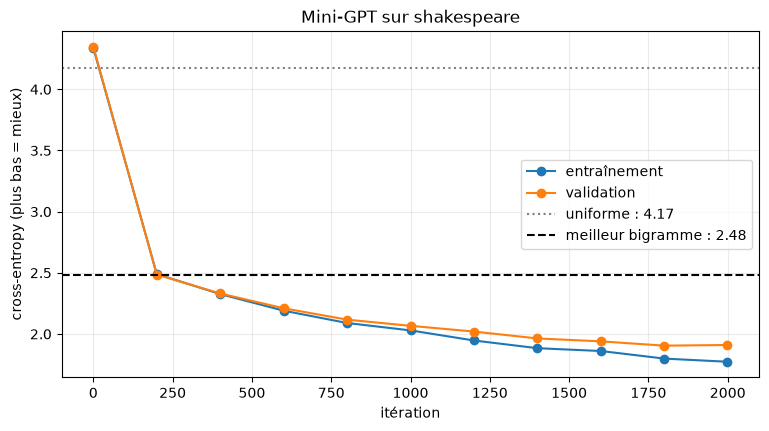

val finale : 1.910 | bigramme : 2.482 | gain dû au contexte : 0.572


In [4]:
# Meilleur bigramme possible : comptage + lissage (chapitre 1)
N = torch.ones(V, V)
N.index_put_((train_data[:-1], train_data[1:]), torch.ones(len(train_data) - 1), accumulate=True)
P = N / N.sum(1, keepdim=True)
loss_bigramme = -P[val_data[:-1], val_data[1:]].log().mean().item()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(historique["pas"], historique["train"], marker="o", label="entraînement")
ax.plot(historique["pas"], historique["val"], marker="o", label="validation")
ax.axhline(math.log(V), color="gray", ls=":", label=f"uniforme : {math.log(V):.2f}")
ax.axhline(loss_bigramme, color="black", ls="--", label=f"meilleur bigramme : {loss_bigramme:.2f}")
ax.set_xlabel("itération"); ax.set_ylabel("cross-entropy (plus bas = mieux)")
ax.set_title(f"Mini-GPT sur {CORPUS}"); ax.legend(); ax.grid(alpha=.25); plt.show()
print(f"val finale : {historique['val'][-1]:.3f} | bigramme : {loss_bigramme:.3f} | gain dû au contexte : {loss_bigramme - historique['val'][-1]:.3f}")

**Comment interpréter :**
- **train ↓ et val ↓ ensemble** : le modèle apprend des régularités qui se généralisent. Il n'a pas fini : plus de pas ou un modèle plus grand ferait mieux.
- **train ↓ mais val ↑** : **surapprentissage** : le modèle récite son corpus au lieu d'en tirer des règles.
- **Écart train/val faible** ici : avec 1 M de caractères et 200 000 paramètres, le modèle est loin de pouvoir tout mémoriser.

## 4. Traduire la loss : la perplexité

La loss est une moyenne de $-\log p$. Son exponentielle, la **perplexité**, s'interprète comme « le nombre de caractères entre lesquels le modèle hésite en moyenne » :

$$\text{perplexité} = e^{\mathcal{L}}$$

In [5]:
for nom, L in [("uniforme", math.log(V)), ("bigramme", loss_bigramme), ("mini-GPT", historique["val"][-1])]:
    print(f"{nom:10s} loss {L:.3f} -> perplexité {math.exp(L):5.1f} caractères")

uniforme   loss 4.174 -> perplexité  65.0 caractères
bigramme   loss 2.482 -> perplexité  12.0 caractères
mini-GPT   loss 1.910 -> perplexité   6.8 caractères


## 5. Le modèle utilise-t-il vraiment le contexte ? La loss par position

À la position `t` d'une fenêtre, le modèle a vu `t + 1` caractères. S'il exploite le contexte, sa loss doit **baisser avec `t`**. Le bigramme, lui, a la même loss partout.

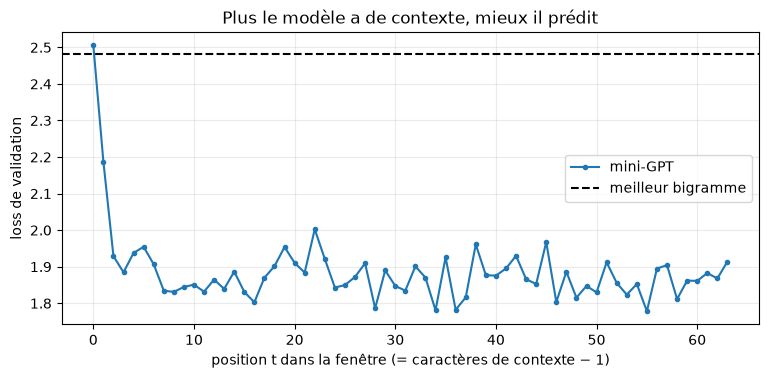

position 0 : 2.51 | position 10 : 1.85 | position 63 : 1.91


In [6]:
@torch.no_grad()
def loss_par_position(model, n_batchs=20):
    model.eval()
    total = torch.zeros(block_size)
    for _ in range(n_batchs):
        xb, yb = minigpt.get_batch(val_data, 64, block_size, device)
        logits, _ = model(xb)
        l = F.cross_entropy(logits.transpose(1, 2), yb, reduction="none")   # (B, T) : une perte par position
        total += l.mean(0).cpu()
    model.train()
    return total / n_batchs

lp = loss_par_position(model)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(range(block_size), lp, marker=".", label="mini-GPT")
ax.axhline(loss_bigramme, color="black", ls="--", label="meilleur bigramme")
ax.set_xlabel("position t dans la fenêtre (= caractères de contexte − 1)"); ax.set_ylabel("loss de validation")
ax.set_title("Plus le modèle a de contexte, mieux il prédit"); ax.legend(); ax.grid(alpha=.25); plt.show()
print(f"position 0 : {lp[0]:.2f} | position 10 : {lp[10]:.2f} | position {block_size - 1} : {lp[-1]:.2f}")

À la position 0, le mini-GPT n'a qu'un caractère : il fait à peu près comme un bigramme. Dès quelques caractères de contexte, il fait **nettement mieux**. C'est la preuve chiffrée que l'attention sert à quelque chose.

## 6. Qu'ont appris les têtes d'attention ?

Recalculons les poids d'attention de chaque tête sur un extrait de validation. Chaque ligne = une position qui « regarde » ; chaque colonne = une position regardée.

'rina, this I know,\nShe is no'


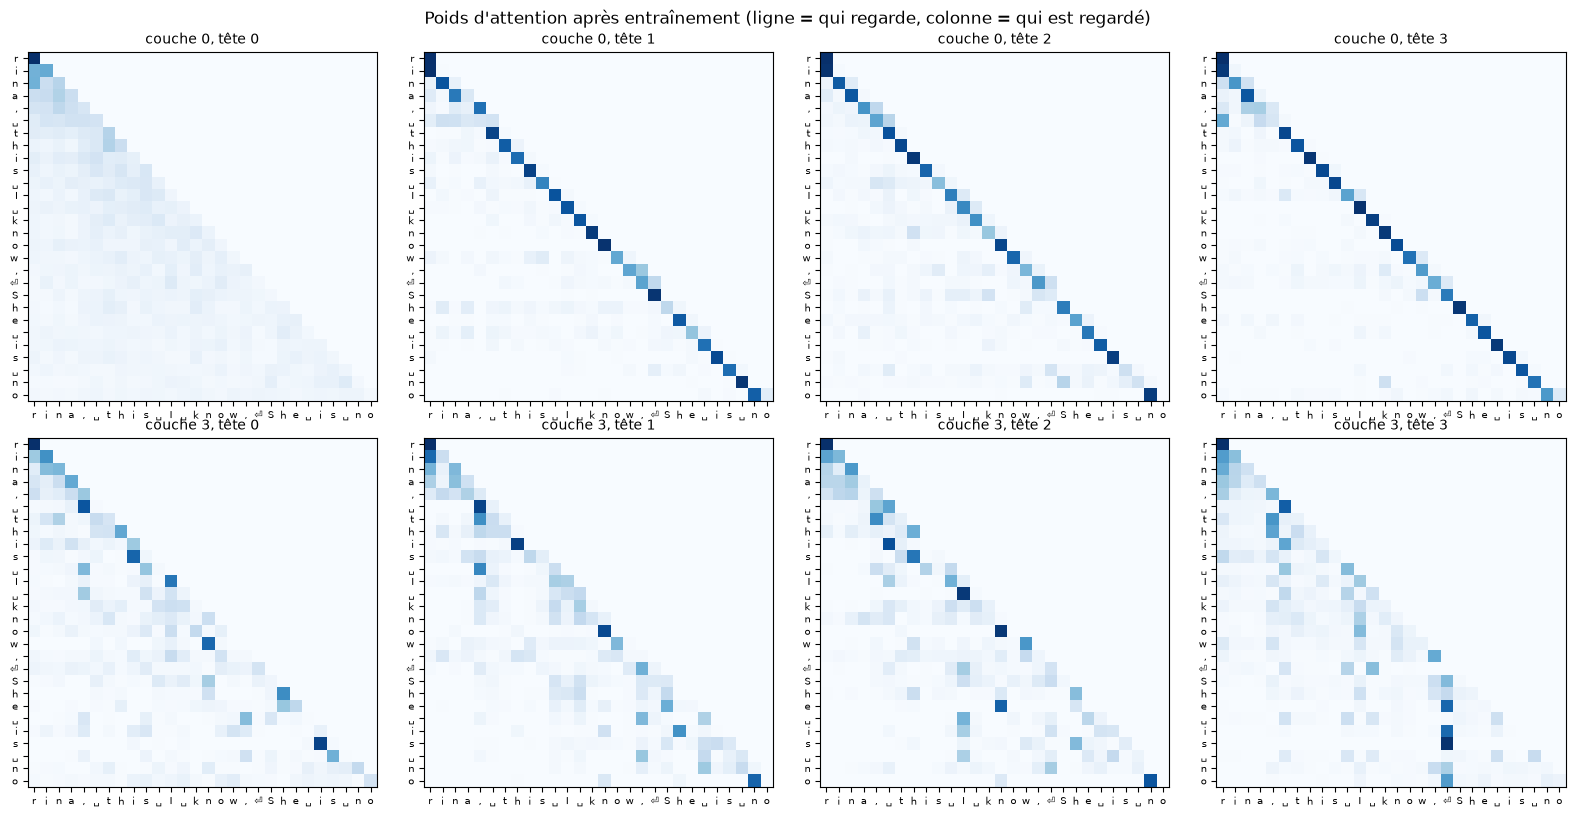

In [7]:
@torch.no_grad()
def poids_attention(model, idx, couche):
    """Poids (n_head, T, T) de la couche demandée, pour une séquence idx de forme (1, T)."""
    model.eval()
    entree = {}
    h = model.blocks[couche].ln1.register_forward_hook(lambda m, e, s: entree.setdefault("x", s))
    model(idx); h.remove(); model.train()
    x, T = entree["x"], idx.shape[1]
    poids = []
    for tete in model.blocks[couche].sa.heads:
        w = tete.query(x) @ tete.key(x).transpose(-2, -1) * tete.key.out_features ** -0.5
        w = w.masked_fill(tete.tril[:T, :T] == 0, float("-inf"))
        poids.append(F.softmax(w, dim=-1)[0].cpu())
    return torch.stack(poids)

extrait = val_data[1000:1028].unsqueeze(0).to(device)
lettres = [{"\n": "⏎", " ": "␣"}.get(c, c) for c in tok.decode(extrait[0])]
print(repr(tok.decode(extrait[0])))
fig, axes = plt.subplots(2, n_head, figsize=(4 * n_head, 8.2))
for r, couche in enumerate([0, n_layer - 1]):
    W = poids_attention(model, extrait, couche)
    for h in range(n_head):
        ax = axes[r, h]
        ax.imshow(W[h], cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(range(len(lettres)), lettres, fontsize=7); ax.set_yticks(range(len(lettres)), lettres, fontsize=7)
        ax.set_title(f"couche {couche}, tête {h}", fontsize=10)
fig.suptitle("Poids d'attention après entraînement (ligne = qui regarde, colonne = qui est regardé)")
plt.tight_layout(); plt.show()

**Ce qu'on peut chercher :**
- la **diagonale** : la tête regarde surtout le caractère **courant** (fréquent dans la première couche : elle recopie l'identité du caractère dans une autre « forme ») ;
- une **diagonale décalée** : la tête regarde le caractère **précédent** (comme la tête construite à la main au notebook 05) ;
- des colonnes sombres sur les **espaces** ou les **retours à la ligne** : la tête repère le **début du mot** ou de la ligne courante ;
- des têtes plus **diffuses** : elles font une moyenne sur un passé large (le « style » général).

Les têtes ne sont pas programmées : ces spécialisations **émergent** de la descente de gradient.

## 7. Générer du texte

### Le modèle entraîné

In [8]:
model.eval()
torch.manual_seed(42)
debut = torch.full((1, 1), tok.stoi["\n"], dtype=torch.long, device=device)
print(tok.decode(model.generate(debut, max_new_tokens=400)[0]))



KIDY LEONCE:
Cay the my consure, on annow no fe thou fear heed lams,
To dreath be to our ungule sead, that is u
ceavie them couse to hing the how bear?

ICINGIA:
O he devannot hear, thoug.

POMIO, but Wellow, thee husuedon'd
Mentencelf, but are to ne this mough wer
seeque.

DUKINGARENT:
The ancomb word thour fasce's of I to him.

First feartent:
Sthis hall stemant mering; o-hightor, the down thei


Comparé au bigramme du notebook 02 : des **mots réels** ou plausibles, des **noms de personnages en majuscules suivis de `:`**, des répliques séparées par des lignes vides. Le sens global reste absent : 200 000 paramètres et 64 caractères de contexte, c'est très peu.

### La température

Avant le softmax, on peut **diviser les logits** par une température $\tau$ :
- $\tau < 1$ : distribution plus **pointue** → texte plus sûr, plus répétitif ;
- $\tau = 1$ : la distribution apprise ;
- $\tau > 1$ : distribution plus **plate** → texte plus créatif… et plus fautif.

In [9]:
for tau in [0.5, 1.0, 1.5]:
    torch.manual_seed(42)
    print(f"--- température {tau} ---")
    print(tok.decode(model.generate(debut, max_new_tokens=200, temperature=tau)[0]))
    print()
model.train();

--- température 0.5 ---




AUDY LEONCE:
The the my come and the and the father the and so life,
The reave the man the greatent.

First Mar
And is the mentleart the but lead be the fand he sue.


Second CLAUTESTER:
O hear and m

--- température 1.0 ---




KIDY LEONCE:
Cay the my consure, on annow no fe thou fear heed lams,
To dreath be to our ungule sead, that is u
ceavie them couse to hing the how bear?

ICINGIA:
O he devannot hear, thoug.

POMIO, bu

--- température 1.5 ---




KIDY LY GERCHARD:
we my chard'd, Sooldney noc. Hove eread Edword magry!

KISS:
We that'G ungnly sea
uttion.

Pu

COMEAM Seme:
He:
I'll nobleflencil! Mebough-chos neer devavn if Gic,
Thoug. Whatic, bu



## 8. Expériences à faire

Changez **un seul** paramètre à la fois et comparez la loss de **validation** (pas la qualité « à l'œil ») :

| Expérience | Question |
|---|---|
| `n_layer = 1` puis `n_layer = 6` | la profondeur aide-t-elle à budget de pas égal ? |
| `n_head = 1` puis `n_head = 8` (avec `n_embd = 64`) | plusieurs têtes valent-elles mieux qu'une grosse ? |
| `block_size = 8` puis `128` | regardez la courbe de **loss par position** |
| `CORPUS = "kaamelott"` | mêmes réglages, répliques en français : reconnaît-on les personnages ? |
| `dropout = 0.0` vs `0.2` | l'écart entre train et val change-t-il ? |
| `CORPUS = "platon"` | même modèle, autre langue : que génère-t-il ? |
| `optimizer = torch.optim.SGD(..., lr=1e-3)` | que devient l'entraînement (notebook 02) ? |

## 9. Synthèse du chapitre

| Étape | Ce que chaque position sait faire | Forme clé | Notebook |
|---|---|---|---|
| Bigramme | utiliser le caractère courant | logits `(B, T, V)` | 02, 03 |
| Moyenne cumulative | recevoir une moyenne uniforme du passé | `(B, T, C)` | 05 |
| Self-attention | **choisir** les positions utiles (Q·K) et récupérer V | poids `(B, T, T)` | 05 |
| Multi-head | faire plusieurs recherches en parallèle | concat `(B, T, C)` | 05 |
| FeedForward | traiter localement l'information reçue | `(B, T, 4C)` → `(B, T, C)` | 06 |
| Blocs + résidus + LN | empiler sans perdre le gradient | flux `(B, T, C)` | 07 |
| `lm_head` | produire un score par caractère | `(B, T, V)` | 08 |

**Le problème n'a jamais changé depuis le chapitre 1 :** prédire le caractère suivant, avec la même loss (cross-entropy) et la même boucle (forward, backward, step). Seule la manière de produire les logits a changé.

**Questions de vérification**
1. Pourquoi `estimate_loss` met-il le modèle en `eval()` ?
2. Que signifie une perplexité de 6 ?
3. Pourquoi la loss à la position 0 est-elle proche de celle du bigramme ?
4. Si la loss de validation remontait pendant que celle d'entraînement baisse, que feriez-vous ?
5. Pourquoi juger un modèle sur la loss de validation plutôt que sur un texte généré ?

### Références
- Andrej Karpathy, [*Let's build GPT: from scratch, in code, spelled out*](https://www.youtube.com/watch?v=kCc8FmEb1nY) (2023) et son code [ng-video-lecture](https://github.com/karpathy/ng-video-lecture) — partie « training » et « scaling up the model ».
- A. Karpathy, [nanoGPT](https://github.com/karpathy/nanoGPT) — entraînement de GPT-2 sur OpenWebText.
- I. Goodfellow, Y. Bengio, A. Courville, [*Deep Learning*](https://www.deeplearningbook.org/), §5.2 (capacité, sur- et sous-apprentissage) et §7.8 (*early stopping*).
- A. Holtzman et al., [*The Curious Case of Neural Text Degeneration*](https://arxiv.org/abs/1904.09751), ICLR 2020 — température et stratégies d'échantillonnage.
- J. Kaplan et al., [*Scaling Laws for Neural Language Models*](https://arxiv.org/abs/2001.08361), 2020 — comment la loss dépend de la taille du modèle et des données.